# PT-03 - Regressao Linear Manual

**Aluno:** Valentim S. A. Neto  
**Matricula:** 2019027210  
**Disciplina:** Aprendizado de Maquina

Os coeficientes e as metricas sao calculados manualmente; `train_test_split` e usado somente para separar os dados.

## Funcoes

A inclinacao e o intercepto seguem as formulas de minimos quadrados do enunciado. O RSE usa `n-2` graus de liberdade e o R2 usa a soma total de quadrados calculada no conjunto de teste.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

def ajustar_regressao_linear(x, y):
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    n = x.size
    denominador = n * np.sum(x**2) - np.sum(x)**2
    if np.isclose(denominador, 0):
        raise ValueError("x precisa possuir variacao")
    beta1 = (n*np.sum(x*y) - np.sum(x)*np.sum(y)) / denominador
    beta0 = (np.sum(y) - beta1*np.sum(x)) / n
    return beta0, beta1

def prever(x, beta0, beta1):
    return beta0 + beta1*np.asarray(x, dtype=float)

def calcular_metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    sse = np.sum((y_real-y_pred)**2)
    rse = np.sqrt(sse/(len(y_real)-2))
    r2 = 1 - sse/np.sum((y_real-y_real.mean())**2)
    return rse, r2


## Parte 1 - Altura e peso

Como o enunciado pede avaliacao no teste mas nao especifica a divisao nesta parte, adotamos 80%/20% e `random_state=42`, igual a parte 2.

beta0=-42.178609; beta1=63.131719; RSE=1.734641; R2=0.978299


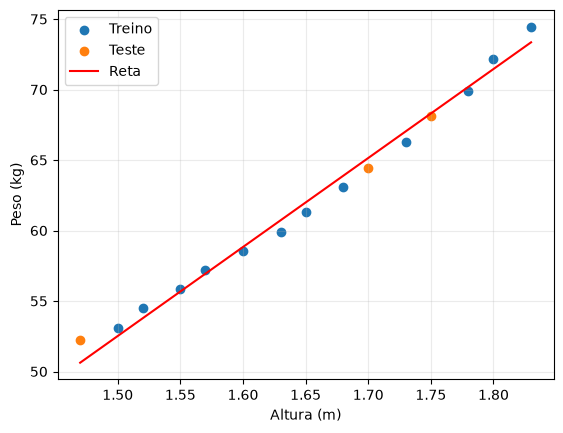

In [2]:
X = np.array([1.47,1.50,1.52,1.55,1.57,1.60,1.63,1.65,1.68,1.70,1.73,1.75,1.78,1.80,1.83])
y = np.array([52.21,53.12,54.48,55.84,57.20,58.57,59.93,61.29,63.11,64.47,66.28,68.10,69.92,72.19,74.46])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
beta0,beta1=ajustar_regressao_linear(X_train,y_train)
y_pred=prever(X_test,beta0,beta1)
rse,r2=calcular_metricas(y_test,y_pred)
print(f"beta0={beta0:.6f}; beta1={beta1:.6f}; RSE={rse:.6f}; R2={r2:.6f}")
grade=np.linspace(X.min(),X.max(),200)
plt.scatter(X_train,y_train,label="Treino"); plt.scatter(X_test,y_test,label="Teste")
plt.plot(grade,prever(grade,beta0,beta1),color="red",label="Reta")
plt.xlabel("Altura (m)"); plt.ylabel("Peso (kg)"); plt.legend(); plt.grid(alpha=.25); plt.show()


**Resultado.** O RSE foi **1.735 kg** e o R2 foi **0.9783**. Neste pequeno conjunto, o modelo explica quase toda a variacao dos pesos de teste.

## Parte 2 - Dataset tips

beta0=0.925236; beta1=0.106964; RSE=0.770077; R2=0.544938
Previsao para conta de US$ 80: US$ 9.48


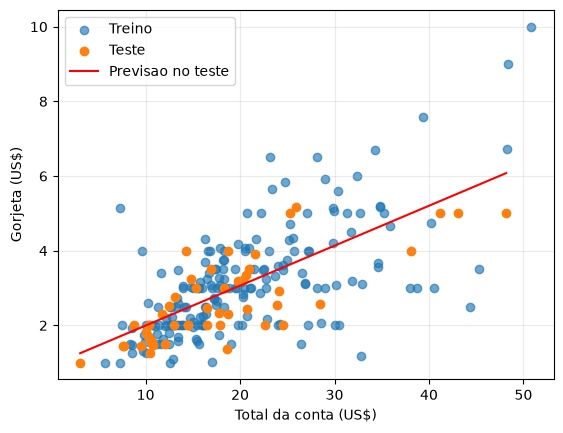

In [3]:
tips=pd.read_csv("tips.csv")
X=tips["total_bill"].to_numpy(); y=tips["tip"].to_numpy()
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=42)
beta0,beta1=ajustar_regressao_linear(X_train,y_train)
y_pred=prever(X_test,beta0,beta1)
rse,r2=calcular_metricas(y_test,y_pred)
gorjeta80=prever(80,beta0,beta1)
print(f"beta0={beta0:.6f}; beta1={beta1:.6f}; RSE={rse:.6f}; R2={r2:.6f}")
print(f"Previsao para conta de US$ 80: US$ {gorjeta80:.2f}")
ordem=np.argsort(X_test)
plt.scatter(X_train,y_train,label="Treino",alpha=.65); plt.scatter(X_test,y_test,label="Teste")
plt.plot(X_test[ordem],y_pred[ordem],color="red",label="Previsao no teste")
plt.xlabel("Total da conta (US$)"); plt.ylabel("Gorjeta (US$)"); plt.legend(); plt.grid(alpha=.25); plt.show()


**Resultado.** No teste, RSE = **US$ 0.770** e R2 = **0.5449**. Para uma conta de **US$ 80**, a extrapolacao linear estima uma gorjeta de **US$ 9.48**. Como US$ 80 esta acima do maior total observado, essa previsao deve ser interpretada com cautela.